# R-SES-002: Menentukan Hiposenter dengan Metode Geiger
**FAHIMAH RAIHANAH**

**H061251010**

Recipe ini mengikuti format **Bab 2.4 buku AI Cookbook untuk Earth Sciences****:

**Problem → Minimal Theory → Prompt → Code → Result → Optional Check** (ditambah *Run record*)

| Keterangan | Isi |
|---|---|
| ID recipe | `R-SES-002` (prompt pendamping: `P-SES-002`) |
| Level | Mahasiswa geofisika semester 3 (Python dasar, aljabar linear dasar) |
| Library | `numpy`, `pandas`, `matplotlib` |
| Data | Waktu tiba gelombang P **sintetis** (dibuat di notebook) |
| Metode | Geiger (inversi linear iteratif, bentuk **G Δm = r**), diverifikasi dengan grid search |

**Cara pakai:** jalankan sel dari atas ke bawah (*Run All*). Hasil file akan muncul di folder `results/r-ses-002/` di sebelah file notebook ini.

---
## 1. Problem

**Pertanyaan ilmiah:** diketahui waktu tiba gelombang P di beberapa stasiun seismometer. Di mana hiposenter gempa (x, y, kedalaman) dan kapan gempa itu terjadi (*origin time*)?

**Batas keputusan:** ini latihan memahami cara kerja inversi lokasi gempa dengan model kecepatan **homogen**. Hasilnya bukan lokasi resmi gempa.

### Kontrak input dan constraint

| Hal | Aturan |
|---|---|
| Input | Tabel `stasiun`, `x_km`, `y_km`, `waktu_P_s`. Koordinat Kartesius lokal (x ke timur, y ke utara), stasiun di permukaan (z = 0), waktu tiba dalam detik |
| Model | Kecepatan gelombang P homogen, `Vp = 6,0 km/s` (asumsi, bukan hasil pengukuran) |
| Tidak boleh | Mengubah data input. Menjalankan lokasi bila stasiun kurang dari 4 |
| Library | Hanya numpy, pandas, matplotlib. Tidak ada akses internet |
| Output | `results/r-ses-002/hasil_hiposenter.csv`, `residual_stasiun.csv`, `peta_hiposenter.png`, `run_record.json` |

---
## 2. Minimal Theory

**Ada 4 hal yang tidak diketahui:** posisi hiposenter $(x, y, z)$ dan origin time $t_0$. Kita kumpulkan dalam vektor $\mathbf{m} = [x,\ y,\ z,\ t_0]$. Karena ada 4 yang dicari, kita butuh **minimal 4 stasiun**, dan lebih banyak lebih baik.

**Waktu tempuh.** Dengan kecepatan homogen, waktu tiba P di stasiun ke-$i$ (koordinat $x_i, y_i, z_i$) adalah

$$t_i = t_0 + \frac{\sqrt{(x_i-x)^2 + (y_i-y)^2 + (z_i-z)^2}}{V_p}$$

**Masalahnya tidak linear** (ada akar kuadrat), jadi tidak bisa diselesaikan langsung. Ide metode **Geiger**:
1. Tebak hiposenter awal $\mathbf{m}_0$.
2. Hitung waktu tiba prediksi $t^{hit}_i$, lalu **residual** $r_i = t^{obs}_i - t^{hit}_i$.
3. Linearkan di sekitar tebakan (hanya suku turunan pertama), sehingga muncul sistem persamaan linear

$$\mathbf{G}\,\Delta\mathbf{m} = \mathbf{r}$$

dengan baris matriks $\mathbf{G}$ untuk stasiun ke-$i$ berisi turunan waktu tiba terhadap tiap parameter:
$\left[-\dfrac{x_i-x}{V_p d_i},\ -\dfrac{y_i-y}{V_p d_i},\ -\dfrac{z_i-z}{V_p d_i},\ 1\right]$, dengan $d_i$ = jarak hiposenter ke stasiun.

4. Selesaikan $\Delta\mathbf{m}$ dengan kuadrat terkecil, perbarui $\mathbf{m} \leftarrow \mathbf{m} + \Delta\mathbf{m}$, **ulangi** sampai perubahannya sangat kecil.

**RMS residual** $= \sqrt{\frac{1}{n}\sum r_i^2}$ mengukur seberapa cocok model dengan data. Nilainya idealnya mendekati tingkat noise pembacaan waktu tiba.

**Ketidakpastian.** Dari matriks $\mathbf{G}$ kita dapat perkiraan galat 1-sigma tiap parameter:
$\sigma_m = \sqrt{\mathrm{diag}\left(\sigma^2 (\mathbf{G}^T\mathbf{G})^{-1}\right)}$, dengan $\sigma^2 = \mathrm{RMS}^2\, n/(n-4)$.

**Asumsi dan keterbatasan:** (1) bumi dianggap homogen dengan Vp konstan, padahal kecepatan sebenarnya bertambah terhadap kedalaman; (2) stasiun di permukaan datar; (3) hanya gelombang P yang dipakai; (4) kedalaman dijaga tidak negatif.

---
## 3. Prompt (`P-SES-002`)

Struktur dari Bab 2.1: **P = ⟨R, T, C, I, K, O, Q, V⟩**. Bagian `[...]` adalah placeholder yang kamu isi sendiri.

```text
R (Role)        : Asisten analisis seismologi dengan Python (numpy, pandas, matplotlib).
T (Task)        : Tentukan hiposenter (x, y, z) dan origin time dari waktu tiba P di [CSV_PATH]
                  dengan metode Geiger (Vp homogen [VP_KMS] km/s), lalu verifikasi dengan grid search.
C (Context)     : Latihan kuliah Seismologi untuk memahami inversi G m = d.
                  Bukan lokasi resmi gempa.
I (Input)       : Hanya [CSV_PATH] dengan kolom stasiun, x_km, y_km, waktu_P_s.
                  Koordinat Kartesius lokal (x timur, y utara), stasiun di z = 0,
                  kedalaman positif ke bawah, waktu dalam detik.
K (Constraints) : Jangan ubah file input. Minimal 4 stasiun; kalau kurang, berhenti dan laporkan.
                  Kedalaman tidak boleh negatif. Jangan mengganti Vp sendiri.
                  Pakai hanya numpy, pandas, matplotlib. Tidak ada akses jaringan.
O (Output)      : [OUTPUT_DIR]/hasil_hiposenter.csv, residual_stasiun.csv,
                  peta_hiposenter.png, run_record.json
Q (Quality)     : Laporkan RMS residual (detik), ketidakpastian 1-sigma tiap parameter,
                  jumlah iterasi, dan status konvergen. Pisahkan observasi dari inferensi.
V (Verification): Bandingkan dengan grid search (selisih harus kecil). Hitung manual satu
                  waktu tempuh. Uji sensitivitas terhadap noise dan jumlah stasiun.
                  Jika ada check gagal, berhenti dan laporkan.
```

---
## 4. Code

### 4.1 Setup dan parameter

In [1]:
import os, json, hashlib, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --- parameter (sesuai placeholder di prompt) ---
VP = 6.0                 # km/s, kecepatan gelombang P homogen (asumsi)
SIGMA_PICK = 0.1         # detik, noise pembacaan waktu tiba (untuk data sintetis)
OUTPUT_DIR = "results/r-ses-002"
CSV_PATH = os.path.join(OUTPUT_DIR, "pick_sintetis.csv")

SEED = 4
RNG = np.random.default_rng(SEED)      # seed tetap: hasil bisa diulang persis
os.makedirs(OUTPUT_DIR, exist_ok=True)
print("Parameter siap. Output akan disimpan di:", OUTPUT_DIR)

Parameter siap. Output akan disimpan di: results/r-ses-002


### 4.2 Fungsi waktu tempuh
Satu fungsi kecil yang dipakai berulang kali. Koordinat dalam km (x timur, y utara, z kedalaman positif ke bawah).

In [2]:
def waktu_tempuh(hipo_xyz, sta_xyz, vp):
    """Waktu tempuh gelombang P (detik) dari hiposenter ke tiap stasiun."""
    jarak = np.linalg.norm(sta_xyz - np.asarray(hipo_xyz), axis=1)
    return jarak / vp

print("Contoh: jarak 60 km dengan Vp 6 km/s ->", 60 / 6.0, "detik")

Contoh: jarak 60 km dengan Vp 6 km/s -> 10.0 detik


### 4.3 Membuat data sintetis
Kita tentukan hiposenter dan origin time "sebenarnya", lalu hitung waktu tiba di 7 stasiun dan tambahkan noise acak 0,1 detik.
Karena kita yang membuatnya, jawaban benar diketahui. Ini dipakai untuk mengecek hasil. Pada data nyata, jawaban benar tidak ada.

In [3]:
HIPO_BENAR = np.array([62.0, 41.0, 12.0])    # x, y, z (km)
T0_BENAR = 3.0                               # detik

stasiun = pd.DataFrame({
    "stasiun": list("ABCDEFG"),
    "x_km": [10, 90, 96, 55, 6, 40, 72],
    "y_km": [12, 8, 62, 96, 78, 45, 30],
})
sta_xyz_benar = np.column_stack([stasiun.x_km, stasiun.y_km, np.zeros(len(stasiun))])
stasiun["waktu_P_s"] = (T0_BENAR + waktu_tempuh(HIPO_BENAR, sta_xyz_benar, VP)
                        + RNG.normal(0, SIGMA_PICK, len(stasiun))).round(3)

stasiun.to_csv(CSV_PATH, index=False)        # simpan sebagai file input resmi recipe
print(f"Data pick disimpan: {CSV_PATH} ({len(stasiun)} stasiun)")
stasiun

Data pick disimpan: results/r-ses-002/pick_sintetis.csv (7 stasiun)


,stasiun,x_km,y_km,waktu_P_s
0,A,10,12,13.058
1,B,90,8,10.468
2,C,96,62,10.121
3,D,55,96,12.520
4,E,6,78,14.200
5,F,40,45,7.229
6,G,72,30,6.122


### 4.4 Memuat dan memvalidasi input
Sesuai kontrak: kolom lengkap, tidak ada nilai hilang, minimal 4 stasiun, nama stasiun unik. Data **tidak diubah**.

In [4]:
data = pd.read_csv(CSV_PATH)                 # baca ulang dari file, seperti pada kasus nyata
kolom_wajib = ["stasiun", "x_km", "y_km", "waktu_P_s"]

cek_input = {
    "kolom_lengkap": set(kolom_wajib).issubset(data.columns),
    "tidak_ada_nilai_hilang": int(data[kolom_wajib].isna().sum().sum()) == 0,
    "minimal_4_stasiun": len(data) >= 4,
    "nama_stasiun_unik": data["stasiun"].is_unique,
    "waktu_berhingga": bool(np.isfinite(data["waktu_P_s"]).all()),
}
for nama, lolos in cek_input.items():
    print(("LOLOS  " if lolos else "GAGAL  ") + nama)
assert all(cek_input.values()), "Validasi input gagal, hentikan recipe dan periksa datanya."

sta_xyz = np.column_stack([data.x_km, data.y_km, np.zeros(len(data))])   # stasiun di z = 0
t_obs = data["waktu_P_s"].to_numpy()
n_sta = len(data)
print(f"\nJumlah stasiun: {n_sta} (parameter yang dicari: 4)")

LOLOS  kolom_lengkap
LOLOS  tidak_ada_nilai_hilang
LOLOS  minimal_4_stasiun
LOLOS  nama_stasiun_unik
LOLOS  waktu_berhingga

Jumlah stasiun: 7 (parameter yang dicari: 4)


### 4.5 Metode Geiger
Ini inti recipe. Perhatikan kaitannya dengan teori: `G` berisi turunan waktu tiba, `r` adalah residual, `lstsq` menyelesaikan G Δm = r.

In [5]:
def matriks_G(m, sta_xyz, vp):
    """Matriks turunan G (n x 4) pada tebakan m = [x, y, z, t0]."""
    selisih = sta_xyz - m[:3]
    jarak = np.maximum(np.linalg.norm(selisih, axis=1), 1e-6)
    return np.column_stack([-selisih / (vp * jarak[:, None]), np.ones(len(jarak))])

def residual(m, sta_xyz, t_obs, vp):
    """Residual = waktu tiba teramati - waktu tiba hitung."""
    return t_obs - (m[3] + waktu_tempuh(m[:3], sta_xyz, vp))

def geiger(sta_xyz, t_obs, vp, m0, maks_iter=20, tol_km=1e-3):
    m = np.array(m0, float)
    riwayat = [m.copy()]
    rms = [np.sqrt(np.mean(residual(m, sta_xyz, t_obs, vp) ** 2))]
    konvergen = False
    for _ in range(maks_iter):
        r = residual(m, sta_xyz, t_obs, vp)
        G = matriks_G(m, sta_xyz, vp)
        dm, *_ = np.linalg.lstsq(G, r, rcond=None)        # selesaikan G dm = r
        m = m + dm
        m[2] = max(m[2], 0.0)                             # kedalaman tidak boleh negatif
        riwayat.append(m.copy())
        rms.append(np.sqrt(np.mean(residual(m, sta_xyz, t_obs, vp) ** 2)))
        if np.linalg.norm(dm[:3]) < tol_km:               # perubahan sangat kecil -> berhenti
            konvergen = True
            break
    return m, np.array(riwayat), np.array(rms), konvergen

def ketidakpastian(m, sta_xyz, rms_akhir, vp):
    n = len(sta_xyz)
    G = matriks_G(m, sta_xyz, vp)
    sigma2 = rms_akhir ** 2 * n / max(n - 4, 1)
    return np.sqrt(np.diag(sigma2 * np.linalg.inv(G.T @ G)))

# tebakan awal: di tengah jaringan stasiun, kedalaman 10 km
m0 = [sta_xyz[:, 0].mean(), sta_xyz[:, 1].mean(), 10.0, t_obs.min()]
m_est, riwayat, rms_iter, konvergen = geiger(sta_xyz, t_obs, VP, m0)
sig_m = ketidakpastian(m_est, sta_xyz, rms_iter[-1], VP)

print(f"Tebakan awal : x={m0[0]:.1f}, y={m0[1]:.1f}, z={m0[2]:.1f} km, t0={m0[3]:.2f} s")
print(f"Konvergen    : {konvergen} setelah {len(riwayat) - 1} iterasi")
tabel_iter = pd.DataFrame(riwayat, columns=["x_km", "y_km", "z_km", "t0_s"]).round(3)
tabel_iter["RMS_s"] = rms_iter.round(4)
tabel_iter.index.name = "iterasi"
tabel_iter

Tebakan awal : x=52.7, y=47.3, z=10.0 km, t0=6.12 s
Konvergen    : True setelah 5 iterasi


,x_km,y_km,z_km,t0_s,RMS_s
iterasi,,,,,
0,52.714,47.286,10.000,6.122,3.2371
1,61.309,40.562,15.329,2.973,0.2100
2,61.455,40.541,12.241,2.996,0.0691
3,61.458,40.540,12.057,2.990,0.0671
4,61.459,40.539,12.053,2.990,0.0671
5,61.459,40.539,12.053,2.990,0.0671


### 4.6 Verifikasi dengan grid search
Cara kedua yang sepenuhnya berbeda: coba **semua titik** pada grid 1 km, hitung RMS residual di tiap titik, ambil yang terkecil. Origin time di tiap titik dihitung langsung sebagai rata-rata (t_obs - waktu tempuh). Lambat tetapi hampir pasti menemukan minimum global, cocok sebagai pembanding.

In [6]:
def grid_search(sta_xyz, t_obs, vp, xs, ys, zs):
    X, Y, Z = np.meshgrid(xs, ys, zs, indexing="ij")
    titik = np.stack([X, Y, Z], axis=-1)[..., None, :]                  # (nx, ny, nz, 1, 3)
    jarak = np.linalg.norm(sta_xyz[None, None, None, :, :] - titik, axis=-1)   # (nx, ny, nz, n)
    tt = jarak / vp
    t0 = (t_obs - tt).mean(axis=-1, keepdims=True)                      # t0 optimal tiap titik
    rms = np.sqrt(((t_obs - tt - t0) ** 2).mean(axis=-1))               # (nx, ny, nz)
    i = np.unravel_index(np.argmin(rms), rms.shape)
    return np.array([xs[i[0]], ys[i[1]], zs[i[2]]]), float(rms[i]), rms, i

xs = np.arange(0, 101, 1.0)
ys = np.arange(0, 101, 1.0)
zs = np.arange(0, 41, 1.0)
hipo_grid, rms_grid, rms_3d, idx_min = grid_search(sta_xyz, t_obs, VP, xs, ys, zs)
print(f"Grid search : x={hipo_grid[0]:.0f}, y={hipo_grid[1]:.0f}, z={hipo_grid[2]:.0f} km (RMS {rms_grid:.3f} s)")
print(f"Geiger      : x={m_est[0]:.2f}, y={m_est[1]:.2f}, z={m_est[2]:.2f} km (RMS {rms_iter[-1]:.3f} s)")

Grid search : x=61, y=40, z=12 km (RMS 0.096 s)
Geiger      : x=61.46, y=40.54, z=12.05 km (RMS 0.067 s)


### 4.7 Grafik hasil
Tiga panel: (a) peta jalur iterasi Geiger, (b) RMS tiap iterasi, (c) peta RMS dari grid search pada kedalaman terbaik. Daerah paling terang (kuning) di (c) adalah RMS terkecil, yaitu hiposenter.

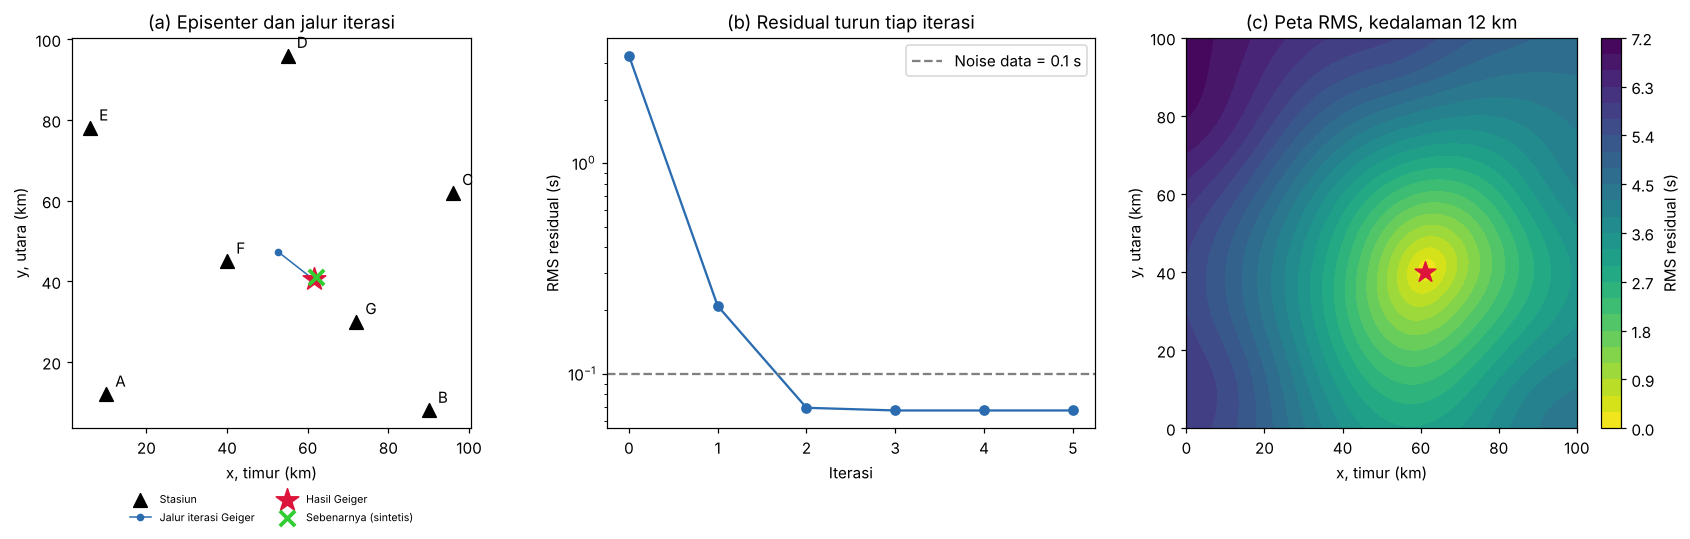

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.9))

# (a) peta
ax[0].scatter(data.x_km, data.y_km, marker="^", s=80, c="k", label="Stasiun", zorder=3)
for _, s in data.iterrows():
    ax[0].annotate(s.stasiun, (s.x_km, s.y_km), textcoords="offset points", xytext=(6, 5))
ax[0].plot(riwayat[:, 0], riwayat[:, 1], "o-", color="#2b6cb0", ms=4, lw=1, label="Jalur iterasi Geiger")
ax[0].scatter(*m_est[:2], marker="*", s=240, c="crimson", label="Hasil Geiger", zorder=4)
ax[0].scatter(*HIPO_BENAR[:2], marker="x", s=100, c="limegreen", linewidths=2.5, label="Sebenarnya (sintetis)", zorder=5)
ax[0].set_xlabel("x, timur (km)"); ax[0].set_ylabel("y, utara (km)")
ax[0].set_title("(a) Episenter dan jalur iterasi")
ax[0].set_aspect("equal")
ax[0].legend(fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2, frameon=False)

# (b) RMS per iterasi
ax[1].semilogy(rms_iter, "o-", color="#2b6cb0")
ax[1].axhline(SIGMA_PICK, color="gray", ls="--", label=f"Noise data = {SIGMA_PICK} s")
ax[1].set_xlabel("Iterasi"); ax[1].set_ylabel("RMS residual (s)")
ax[1].set_title("(b) Residual turun tiap iterasi"); ax[1].legend()

# (c) peta RMS grid search pada kedalaman terbaik
irisan = rms_3d[:, :, idx_min[2]]
cs = ax[2].contourf(xs, ys, irisan.T, levels=25, cmap="viridis_r")
fig.colorbar(cs, ax=ax[2], label="RMS residual (s)")
ax[2].scatter(*hipo_grid[:2], marker="*", s=200, c="crimson")
ax[2].set_xlabel("x, timur (km)"); ax[2].set_ylabel("y, utara (km)")
ax[2].set_title(f"(c) Peta RMS, kedalaman {hipo_grid[2]:.0f} km")
ax[2].set_aspect("equal")

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "peta_hiposenter.png"), dpi=150)
plt.show()

### 4.8 Menyimpan hasil
Residual tiap stasiun penting untuk dilihat: stasiun dengan residual jauh lebih besar dari yang lain bisa jadi punya pembacaan waktu tiba yang salah.

In [8]:
hasil = pd.DataFrame({
    "parameter": ["x", "y", "kedalaman_z", "origin_time_t0"],
    "nilai": m_est,
    "ketidakpastian_1sigma": sig_m,
    "satuan": ["km", "km", "km", "s"],
}).round(3)
hasil.to_csv(os.path.join(OUTPUT_DIR, "hasil_hiposenter.csv"), index=False)

res_sta = data[["stasiun"]].copy()
res_sta["jarak_hiposenter_km"] = np.linalg.norm(sta_xyz - m_est[:3], axis=1).round(1)
res_sta["residual_s"] = residual(m_est, sta_xyz, t_obs, VP).round(3)
res_sta.to_csv(os.path.join(OUTPUT_DIR, "residual_stasiun.csv"), index=False)

print(hasil.to_string(index=False))
print()
print(res_sta.to_string(index=False))

     parameter  nilai  ketidakpastian_1sigma satuan
             x 61.459                  0.345     km
             y 40.539                  0.418     km
   kedalaman_z 12.053                  1.634     km
origin_time_t0  2.990                  0.098      s

stasiun  jarak_hiposenter_km  residual_s
      A                 60.1       0.057
      B                 44.9      -0.011
      C                 42.4       0.062
      D                 57.1       0.009
      E                 68.0      -0.124
      F                 25.0       0.070
      G                 19.2      -0.063


---
## 5. Result

Observasi (dihitung langsung), inferensi (tafsiran), dan keterbatasan dipisah, seperti anjuran Bab 2.1.

In [9]:
galat_horizontal = float(np.linalg.norm(m_est[:2] - HIPO_BENAR[:2]))
galat_kedalaman = float(abs(m_est[2] - HIPO_BENAR[2]))

print("OBSERVASI (dihitung dari data):")
print(f"- Hiposenter hasil Geiger: x = {m_est[0]:.1f} +/- {sig_m[0]:.1f} km, y = {m_est[1]:.1f} +/- {sig_m[1]:.1f} km, "
      f"kedalaman = {m_est[2]:.1f} +/- {sig_m[2]:.1f} km (1-sigma).")
print(f"- Origin time = {m_est[3]:.2f} +/- {sig_m[3]:.2f} s. RMS residual = {rms_iter[-1]:.3f} s, "
      f"konvergen dalam {len(riwayat) - 1} iterasi.")
gx, gy, gz = (int(v) for v in hipo_grid)
print(f"- Grid search memberi titik (x = {gx}, y = {gy}, z = {gz}) km, selisih {np.linalg.norm(m_est[:3] - hipo_grid):.2f} km dari Geiger.")
print(f"- Terhadap jawaban sebenarnya (hanya ada karena data sintetis): galat horizontal {galat_horizontal:.2f} km, "
      f"galat kedalaman {galat_kedalaman:.2f} km.")
print()
print("INFERENSI (tafsiran):")
print("- Dua metode yang sangat berbeda (iteratif linear dan coba-semua-titik) menunjuk lokasi yang sama,")
print("  sehingga solusi ini kemungkinan besar bukan artefak dari tebakan awal.")
rms_diharapkan = SIGMA_PICK * np.sqrt((n_sta - 4) / n_sta)
print(f"- RMS residual ({rms_iter[-1]:.3f} s) sebanding dengan perkiraan dari noise data ({rms_diharapkan:.3f} s). Nilainya lebih kecil")
print(f"  dari noise {SIGMA_PICK} s karena 4 parameter 'menyerap' sebagian noise. Jadi modelnya cukup menjelaskan data.")
print()
print("KETERBATASAN:")
print("- Data sintetis dan model bumi homogen. Pada data nyata, Vp berubah terhadap kedalaman sehingga")
print("  kedalaman bisa bergeser cukup jauh.")
print("- Hanya gelombang P yang dipakai. Origin time dan kedalaman saling mempengaruhi (trade-off).")
print("- Ketidakpastian 1-sigma di atas hanya memperhitungkan noise waktu tiba, bukan kesalahan model kecepatan.")

OBSERVASI (dihitung dari data):
- Hiposenter hasil Geiger: x = 61.5 +/- 0.3 km, y = 40.5 +/- 0.4 km, kedalaman = 12.1 +/- 1.6 km (1-sigma).
- Origin time = 2.99 +/- 0.10 s. RMS residual = 0.067 s, konvergen dalam 5 iterasi.
- Grid search memberi titik (x = 61, y = 40, z = 12) km, selisih 0.71 km dari Geiger.
- Terhadap jawaban sebenarnya (hanya ada karena data sintetis): galat horizontal 0.71 km, galat kedalaman 0.05 km.

INFERENSI (tafsiran):
- Dua metode yang sangat berbeda (iteratif linear dan coba-semua-titik) menunjuk lokasi yang sama,
  sehingga solusi ini kemungkinan besar bukan artefak dari tebakan awal.
- RMS residual (0.067 s) sebanding dengan perkiraan dari noise data (0.065 s). Nilainya lebih kecil
  dari noise 0.1 s karena 4 parameter 'menyerap' sebagian noise. Jadi modelnya cukup menjelaskan data.

KETERBATASAN:
- Data sintetis dan model bumi homogen. Pada data nyata, Vp berubah terhadap kedalaman sehingga
  kedalaman bisa bergeser cukup jauh.
- Hanya gelombang P yang dip

---
## 6. Optional Check

Pengecekan proporsional dengan risikonya. Di sini ada 6 check, dan satu uji sensitivitas yang sangat penting untuk dipahami.

In [10]:
checks = {}

# Check 1: Geiger konvergen sebelum batas iterasi
checks["geiger_konvergen"] = bool(konvergen)

# Check 2: hitung manual satu waktu tempuh, bandingkan dengan fungsi waktu_tempuh
dx, dy, dz = sta_xyz[0] - m_est[:3]
t_manual = (dx**2 + dy**2 + dz**2) ** 0.5 / VP
t_fungsi = waktu_tempuh(m_est[:3], sta_xyz, VP)[0]
checks["waktu_tempuh_manual_sama_fungsi"] = bool(abs(t_manual - t_fungsi) < 1e-9)
print(f"Check 2: stasiun {data.stasiun.iloc[0]}: manual = {t_manual:.4f} s, fungsi = {t_fungsi:.4f} s")

# Check 3: RMS residual tidak lebih dari 2x noise data
checks["rms_dekat_noise(<2x)"] = bool(rms_iter[-1] < 2 * SIGMA_PICK)

# Check 4: Geiger dan grid search sepakat (grid 1 km -> toleransi 2 km)
checks["geiger_sama_grid_search(<2km)"] = bool(np.linalg.norm(m_est[:3] - hipo_grid) < 2.0)

# Check 5: galat terhadap jawaban sebenarnya (hanya untuk data sintetis)
checks["galat_horizontal<3km"] = bool(galat_horizontal < 3.0)
checks["galat_kedalaman<5km"] = bool(galat_kedalaman < 5.0)

for nama, lolos in checks.items():
    print(("LOLOS  " if lolos else "GAGAL  ") + nama)

Check 2: stasiun A: manual = 10.0108 s, fungsi = 10.0108 s
LOLOS  geiger_konvergen
LOLOS  waktu_tempuh_manual_sama_fungsi
LOLOS  rms_dekat_noise(<2x)
LOLOS  geiger_sama_grid_search(<2km)
LOLOS  galat_horizontal<3km
LOLOS  galat_kedalaman<5km


### Uji sensitivitas: noise dan jumlah stasiun
Satu hasil bisa kebetulan bagus. Di sini kita ulangi lokasi **200 kali** dengan noise acak berbeda, lalu lihat galat 3D (jarak ke hiposenter sebenarnya).

Perhatikan skenario **4 stasiun**: jumlah stasiun = jumlah parameter, sehingga data bisa dicocokkan *persis* (RMS mendekati 0) padahal hasilnya bisa melenceng jauh. **RMS kecil bukan berarti lokasi benar.**

In [11]:
def simulasi_galat(idx_sta, sigma, n_ulang=200):
    sta = sta_xyz_benar[idx_sta]
    galat, z_nol = [], 0
    for _ in range(n_ulang):
        t = T0_BENAR + waktu_tempuh(HIPO_BENAR, sta, VP) + RNG.normal(0, sigma, len(sta))
        m0_ = [sta[:, 0].mean(), sta[:, 1].mean(), 10.0, t.min()]
        m_, *_ = geiger(sta, t, VP, m0_)
        galat.append(np.linalg.norm(m_[:3] - HIPO_BENAR))
        z_nol += int(m_[2] <= 1e-6)              # berapa kali kedalaman terdorong ke batas 0 km
    galat = np.array(galat)
    return float(np.median(galat)), float(np.percentile(galat, 90)), 100 * z_nol / n_ulang

semua = list(range(7))
empat = [0, 2, 4, 6]                      # stasiun A, C, E, G
skenario = [("7 stasiun", semua, 0.05), ("7 stasiun", semua, 0.1), ("7 stasiun", semua, 0.3),
            ("4 stasiun", empat, 0.1), ("4 stasiun", empat, 0.3)]
baris = []
for nama, idx, sg in skenario:
    med, p90, pz = simulasi_galat(idx, sg)
    baris.append({"skenario": nama, "noise_s": sg, "galat_median_km": round(med, 2),
                  "galat_p90_km": round(p90, 2), "persen_kedalaman_0km": round(pz, 1)})
sens = pd.DataFrame(baris)
sens

,skenario,noise_s,galat_median_km,galat_p90_km,persen_kedalaman_0km
0,7 stasiun,0.05,0.64,1.42,0.0
1,7 stasiun,0.10,1.23,2.46,0.0
2,7 stasiun,0.30,3.63,10.28,10.0
3,4 stasiun,0.10,2.53,5.98,7.5
4,4 stasiun,0.30,10.20,12.65,34.0


**Cara membaca tabel:** `galat_median_km` adalah galat khas, `galat_p90_km` adalah galat pada 10% kasus terburuk, dan `persen_kedalaman_0km` adalah persentase kasus ketika hasil kedalaman terdorong ke batas 0 km (tanda solusi tidak terkendali oleh data). Jaringan yang lebih padat dan noise yang lebih kecil memberi lokasi yang lebih baik. Dalam laporan, selalu sebut jumlah stasiun dan perkiraan noise pembacaan waktu tiba bersama hasil lokasinya.

---
## 7. Run record

Catatan bukti eksekusi: apa yang dijalankan, pada input apa, dengan versi apa, dan check mana yang lolos. Setiap kali kamu menjalankannya di komputermu, rekamannya ikut diperbarui.

In [12]:
with open(CSV_PATH, "rb") as f:
    sha_input = hashlib.sha256(f.read()).hexdigest()

semua_lolos = all(checks.values())
run_record = {
    "recipe_id": "R-SES-002",
    "prompt_id": "P-SES-002",
    "status": "Executed" if semua_lolos else "Partial",
    "catatan_status": "Dijalankan penuh pada data SINTETIS dengan model kecepatan homogen. Belum diuji pada data nyata.",
    "waktu_eksekusi": pd.Timestamp.now().isoformat(timespec="seconds"),
    "lingkungan": {"python": platform.python_version(), "numpy": np.__version__,
                   "pandas": pd.__version__, "os": platform.system()},
    "input": {"file": CSV_PATH, "sha256": sha_input, "stasiun": n_sta},
    "parameter": {"vp_km_s": VP, "sigma_pick_s": SIGMA_PICK, "seed": SEED},
    "output": {"hiposenter_km": [round(float(v), 3) for v in m_est[:3]],
               "origin_time_s": round(float(m_est[3]), 3),
               "rms_s": round(float(rms_iter[-1]), 4),
               "iterasi": int(len(riwayat) - 1),
               "file": ["hasil_hiposenter.csv", "residual_stasiun.csv", "peta_hiposenter.png", "run_record.json"]},
    "checks": checks,
}
with open(os.path.join(OUTPUT_DIR, "run_record.json"), "w", encoding="utf-8") as f:
    json.dump(run_record, f, indent=2, ensure_ascii=False)

print(json.dumps(run_record, indent=2, ensure_ascii=False))
print("\nFile di", OUTPUT_DIR + ":", sorted(os.listdir(OUTPUT_DIR)))

{
  "recipe_id": "R-SES-002",
  "prompt_id": "P-SES-002",
  "status": "Executed",
  "catatan_status": "Dijalankan penuh pada data SINTETIS dengan model kecepatan homogen. Belum diuji pada data nyata.",
  "waktu_eksekusi": "2026-10-20T14:27:40",
  "lingkungan": {
    "python": "3.13.16",
    "numpy": "2.5.3",
    "pandas": "3.0.5",
    "os": "Linux"
  },
  "input": {
    "file": "results/r-ses-002/pick_sintetis.csv",
    "sha256": "5a79dd9b93b9e12bbad7fc598ac801817f57dfa6b059e4dca472cfc226a67dd6",
    "stasiun": 7
  },
  "parameter": {
    "vp_km_s": 6.0,
    "sigma_pick_s": 0.1,
    "seed": 4
  },
  "output": {
    "hiposenter_km": [
      61.459,
      40.539,
      12.053
    ],
    "origin_time_s": 2.99,
    "rms_s": 0.0671,
    "iterasi": 5,
    "file": [
      "hasil_hiposenter.csv",
      "residual_stasiun.csv",
      "peta_hiposenter.png",
      "run_record.json"
    ]
  },
  "checks": {
    "geiger_konvergen": true,
    "waktu_tempuh_manual_sama_fungsi": true,
    "rms_dekat_no